# Pruebas $t$ e intervalos de confianza

*¿Qué podemos afirmar sobre un parámetro a partir de su estimación?*

En los notebooks anteriores estimamos un modelo de regresión lineal múltiple y calculamos la matriz de varianzas y covarianzas de sus estimadores. Ahora usaremos esos resultados para evaluar afirmaciones sobre los parámetros poblacionales.

Primero construiremos los estadísticos y las decisiones; después comprobaremos los resultados con las funciones de R. Este notebook puede ejecutarse de forma independiente.

## Importamos los datos

Usamos nuevamente la base de Big Andy's Burger Barn de Hill, Griffiths y Lim (2011): 75 observaciones de franquicias en distintas ciudades. `sales` son ingresos mensuales por ventas y `advert` es gasto mensual en publicidad, ambos en miles de dólares. `price` es un índice de precios expresado en dólares.

Cargamos la base desde la misma ruta relativa utilizada en los notebooks 06 y 07.

In [13]:
library(readr)

datos <- read_csv("../data/andy.csv")
head(datos)

Rows: 75 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (3): sales, price, advert

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


# A tibble: 6 × 3
  sales price advert
  <dbl> <dbl>  <dbl>
1  73.2  5.69    1.3
2  71.8  6.49    2.9
3  62.4  5.63    0.8
4  67.4  6.22    0.7
5  89.3  5.02    1.5
6  70.3  6.41    1.3

## Recuperamos el modelo

Estimamos el mismo modelo de regresión lineal múltiple:

$$
sales_i=\beta_1+\beta_2price_i+\beta_3advert_i+u_i.
$$

La pendiente de `price` representa la relación parcial entre precio y ventas, manteniendo fija la publicidad. La pendiente de `advert` representa la relación parcial entre publicidad y ventas, manteniendo fijo el precio.

In [14]:
mco <- lm(sales ~ price + advert, data = datos)
coef(mco)

(Intercept)       price      advert 
 118.913610   -7.907854    1.862584 

## Recuperamos la incertidumbre de las estimaciones

En el notebook 07 utilizamos `vcov()` para obtener la matriz

$$
\widehat{\operatorname{Var}}(\mathbf b)
=s^2(\mathbf X^\top\mathbf X)^{-1}.
$$

La raíz cuadrada de cada elemento de la diagonal es el error estándar de un coeficiente. También necesitamos los grados de libertad residuales $n-k$, donde $k$ incluye la constante.

In [15]:
Vb <- vcov(mco)
se <- sqrt(diag(Vb))

n <- nobs(mco)
k <- length(coef(mco))
gl <- df.residual(mco)

print(se)
print(c(n = n, k = k, gl = gl))

(Intercept)       price      advert 
  6.3516375   1.0959930   0.6831955 
 n  k gl 
75  3 72 


## Planteamos una hipótesis sobre el precio

Queremos evaluar si los datos son compatibles con un coeficiente poblacional de precio igual a cero:

$$
H_0:\beta_2=0,\qquad H_1:\beta_2\neq 0.
$$

La estimación $b_2$ puede ser distinta de cero por variación muestral, incluso cuando $H_0$ es verdadera. El estadístico $t$ mide qué tan lejos se encuentra la estimación del valor propuesto, en unidades de error estándar:

$$
t_2=\frac{b_2-0}{\operatorname{s.e.}(b_2)}.
$$

In [16]:
b2 <- unname(coef(mco)["price"])
se2 <- unname(se["price"])
t_precio <- as.numeric(b2 / se2)

c(b2 = b2, error_estandar = se2, t_observado = t_precio)

            b2 error_estandar    t_observado 
     -7.907854       1.095993      -7.215241 

## ¿Con qué distribución comparamos el estadístico?

Bajo los supuestos clásicos y, para la inferencia exacta en muestras finitas, la normalidad de los errores,

$$
\mathbf u\sim N(\mathbf 0,\sigma^2\mathbf I_n),
$$

tenemos, si $H_0$ es verdadera,

$$
t_2\sim t_{n-k}.
$$

Como estimamos $\sigma^2$ en lugar de conocerla, utilizamos la distribución $t$ de Student con $n-k$ grados de libertad. En el curso tratamos los regresores como deterministas.

## Obtenemos los valores críticos

Esta es una **prueba bilateral (de dos colas)**: la hipótesis alternativa permite desviaciones en ambas direcciones. Por ello, el nivel de significancia $\alpha$ se reparte entre las dos colas, $\alpha/2$ en cada una.

Rechazamos $H_0$ cuando

$$
|t_2|>t_{\alpha/2,n-k}.
$$

`qt(1 - alpha/2, gl)` devuelve el valor crítico positivo. Compararemos las decisiones al 10%, 5% y 1%.

In [17]:
alpha <- c(0.10, 0.05, 0.01)
t_critico <- qt(1 - alpha / 2, df = gl)

decision <- ifelse(abs(t_precio) > t_critico,
                   "Rechazar H0", "No rechazar H0")

data.frame(alpha, t_critico, t_observado = t_precio, decision)

  alpha t_critico t_observado    decision
1  0.10  1.666294   -7.215241 Rechazar H0
2  0.05  1.993464   -7.215241 Rechazar H0
3  0.01  2.645852   -7.215241 Rechazar H0

## Visualizamos la regla bilateral

Las líneas discontinuas marcan los valores críticos para una prueba bilateral al 5%. Las regiones de rechazo están más allá de esas líneas. La línea continua marca el estadístico calculado a partir de los datos.

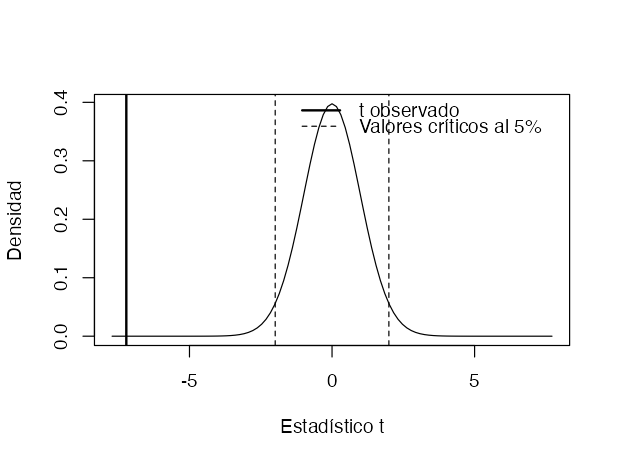

In [18]:
tc05 <- qt(0.975, df = gl)
limite <- max(4, abs(t_precio) + 0.5)

curve(dt(x, df = gl), from = -limite, to = limite,
      xlab = "Estadístico t", ylab = "Densidad", main = "")
abline(v = c(-tc05, tc05), lty = 2)
abline(v = t_precio, lwd = 2)
legend("topright", legend = c("t observado", "Valores críticos al 5%"),
       lty = c(1, 2), lwd = c(2, 1), bty = "n")

## Calculamos el valor $p$

En una prueba bilateral, el valor $p$ es la probabilidad, *suponiendo verdadera $H_0$*, de obtener un estadístico tan alejado de cero como el observado o más:

$$
p=2P(T_{n-k}\geq |t_2|).
$$

En R usamos `pt()` para calcular la probabilidad de la cola derecha. Rechazamos $H_0$ cuando $p<\alpha$.

In [19]:
p_precio <- 2 * pt(abs(t_precio), df = gl, lower.tail = FALSE)

print(c(t_observado = t_precio, valor_p = p_precio))
print(data.frame(alpha, decision_por_p = ifelse(p_precio < alpha,
                                               "Rechazar H0", "No rechazar H0")))

  t_observado       valor_p 
-7.215241e+00  4.423997e-10 
  alpha decision_por_p
1  0.10    Rechazar H0
2  0.05    Rechazar H0
3  0.01    Rechazar H0


## Verificamos los cálculos con `summary()`

Ahora sí examinamos las columnas `t value` y `Pr(>|t|)` del resumen. Los resultados corresponden a las pruebas bilaterales de que cada coeficiente es igual a cero. Para `price`, deben coincidir con los cálculos anteriores, salvo redondeo.

In [20]:
smco <- summary(mco)
print(smco$coefficients)

print(c(t_manual = t_precio,
        t_resumen = smco$coefficients["price", "t value"],
        p_manual = p_precio,
        p_resumen = smco$coefficients["price", "Pr(>|t|)"]))

              Estimate Std. Error   t value     Pr(>|t|)
(Intercept) 118.913610  6.3516375 18.721725 2.214293e-29
price        -7.907854  1.0959930 -7.215241 4.423997e-10
advert        1.862584  0.6831955  2.726283 8.038182e-03
     t_manual     t_resumen      p_manual     p_resumen 
-7.215241e+00 -7.215241e+00  4.423997e-10  4.423997e-10 


## Construimos un intervalo de confianza

Un intervalo de confianza bilateral del 95% para $\beta_2$ es

$$
IC_{95\%}(\beta_2)=
\left[b_2-t_{0.025,n-k}\operatorname{s.e.}(b_2),\;
      b_2+t_{0.025,n-k}\operatorname{s.e.}(b_2)\right].
$$

Primero calculamos sus límites y luego los comparamos con `confint()`. El 95% describe la cobertura del procedimiento bajo muestreo repetido, no la probabilidad de que el parámetro fijo esté dentro de este intervalo particular.

In [21]:
ic_precio <- c(inferior = b2 - tc05 * se2,
               superior = b2 + tc05 * se2)

print(ic_precio)
print(confint(mco, parm = "price", level = 0.95))

  inferior   superior 
-10.092676  -5.723032 
          2.5 %    97.5 %
price -10.09268 -5.723032


## Relacionamos el intervalo con la prueba bilateral

En una prueba bilateral al 5%, rechazamos $H_0:\beta_2=0$ si el cero queda *fuera* del intervalo de confianza del 95%. Comprobamos que ambas reglas producen la misma decisión.

In [22]:
rechazo_t <- abs(t_precio) > tc05
rechazo_ic <- !(ic_precio["inferior"] <= 0 && 0 <= ic_precio["superior"])

c(rechazo_por_t = rechazo_t, rechazo_por_ic = rechazo_ic)

 rechazo_por_t rechazo_por_ic 
          TRUE           TRUE 

## Probamos una hipótesis distinta de cero

Volvamos a la publicidad. Queremos evaluar

$$
H_0:\beta_3=1,\qquad H_1:\beta_3\neq 1.
$$

Puesto que `sales` y `advert` están en miles de dólares, esta hipótesis plantea que mil dólares adicionales de publicidad se asocian con mil dólares adicionales de ingresos mensuales esperados, manteniendo fijo el precio.

El estadístico ahora debe restar el valor propuesto por la hipótesis, no cero:

$$
t_3=\frac{b_3-1}{\operatorname{s.e.}(b_3)}.
$$

In [23]:
b3 <- unname(coef(mco)["advert"])
se3 <- unname(se["advert"])
t_publicidad <- as.numeric((b3 - 1) / se3)
p_publicidad <- 2 * pt(abs(t_publicidad), df = gl, lower.tail = FALSE)

print(c(b3 = b3, error_estandar = se3,
        t_observado = t_publicidad, valor_p = p_publicidad))
print(ifelse(p_publicidad < 0.05, "Rechazar H0", "No rechazar H0"))

            b3 error_estandar    t_observado        valor_p 
     1.8625843      0.6831955      1.2625732      0.2108166 
[1] "No rechazar H0"


## Pruebas de una sola cola

La dirección de la hipótesis alternativa determina qué cola debemos utilizar. Por ejemplo:

- **Cola izquierda:** $H_0:\beta_2\geq 0$ frente a $H_1:\beta_2<0$, para evaluar evidencia de una relación negativa entre precio y ventas.
- **Cola derecha:** $H_0:\beta_3\leq 0$ frente a $H_1:\beta_3>0$, para evaluar evidencia de una relación positiva entre publicidad y ventas.

En ambos casos calculamos el estadístico en la frontera de la hipótesis nula. La alternativa debe definirse antes de observar los resultados, no elegir la cola que produzca el menor valor $p$.

In [24]:
# Cola izquierda: beta_2 < 0
p_izquierda <- pt(t_precio, df = gl)
tc_izquierda <- qt(0.05, df = gl)

# Cola derecha: beta_3 > 0
t_publicidad_cero <- as.numeric(b3 / se3)
p_derecha <- pt(t_publicidad_cero, df = gl, lower.tail = FALSE)
tc_derecha <- qt(0.95, df = gl)

data.frame(
  prueba = c("Precio: cola izquierda", "Publicidad: cola derecha"),
  t_observado = c(t_precio, t_publicidad_cero),
  t_critico = c(tc_izquierda, tc_derecha),
  valor_p = c(p_izquierda, p_derecha),
  decision_5pct = c(ifelse(t_precio < tc_izquierda, "Rechazar H0", "No rechazar H0"),
                    ifelse(t_publicidad_cero > tc_derecha, "Rechazar H0", "No rechazar H0"))
)

                    prueba t_observado t_critico      valor_p decision_5pct
1   Precio: cola izquierda   -7.215241 -1.666294 2.211999e-10   Rechazar H0
2 Publicidad: cola derecha    2.726283  1.666294 4.019091e-03   Rechazar H0

## Interpretación de la evidencia

En el ejemplo de Andy, el coeficiente estimado del precio es negativo (aproximadamente $-7.91$) y rechazamos $H_0:\beta_2=0$ al 5%. En cambio, para la publicidad no rechazamos $H_0:\beta_3=1$ (valor $p$ cercano a 0.21). Esto último **no demuestra** que el coeficiente poblacional sea exactamente igual a 1.

Una estimación indica la magnitud y el signo de una relación parcial en la muestra. Su error estándar permite evaluar la precisión de esa estimación, y una prueba de hipótesis permite contrastar un valor propuesto del parámetro.

Rechazar una hipótesis nula no demuestra que la relación sea causal ni que sea económicamente importante. No rechazarla tampoco demuestra que la hipótesis sea verdadera. Un valor $p$ no es la probabilidad de que $H_0$ sea verdadera.

Al interpretar resultados, debemos considerar conjuntamente la estimación, su incertidumbre, las unidades económicas y los supuestos que justifican la inferencia.

## Para reflexionar

1. Si `price` tiene un coeficiente estimado negativo, ¿eso basta para concluir que $\beta_2<0$? ¿Qué información adicional utilizaste?
2. ¿Por qué el resultado de $H_0:\beta_3=0$ no responde automáticamente la pregunta planteada por $H_0:\beta_3=1$?
3. ¿Qué relación existe entre el intervalo del 95% para $\beta_2$ y la prueba bilateral de $H_0:\beta_2=0$ al 5%?
4. ¿Qué conclusión económica sería excesiva aunque una prueba $t$ rechazara la hipótesis nula?

En el siguiente notebook estudiaremos cómo contrastar **varias restricciones simultáneamente** mediante pruebas $F$.